# 3.2. Practica 2. Análisis, implementación y prueba de técnicas de IA a un Dataset de Redes Sociales para optimizar el tiempo de respuesta.

## Introducción de la actividad.

La IA es una ciencia que tiene su fundamento en la comprensión de entidades inteligentes. La definición de IA y sus áreas de división, debe ser claras y precisas para evitar confusiones.

## Propósito de la actividad

Comprender el funcionamiento y la implementación de técnicas de IA aplicadas a un Dataset de Redes Sociales para optimizar el tiempo de respuesta.

## Instrucciones.

Analicé, implemente y evalué técnicas de IA aplicadas  a un Dataset de Redes Sociales para optimizar el tiempo de respuesta.

## Datos generales

**Alumno:** Marco Sebastián Hernández Parada

**Dataset:** *Twitter US Airline Sentiment* (CrowdFlower, 2016), el mismo de la práctica 3.1: 14,640 tweets dirigidos a seis aerolíneas de Estados Unidos en febrero de 2015, con su sentimiento etiquetado y la fecha de publicación.

**Técnica de IA:** clasificación supervisada de texto (TF-IDF + Regresión Logística) para **priorizar** la atención de los tweets en una cola de servicio al cliente.

**Repositorio:** el notebook completo está disponible en [GitHub](https://github.com/RKCbas/LENGUAJES-DE-CIENCIA-DE-DATOS-B-SICO---PRACTICAS/blob/main/Cuatrimestre%204/9%20-%20T%C3%B3picos%20de%20IA%20para%20la%20transformaci%C3%B3n%20digital/Practica%203.2/An%C3%A1lisis%2C%20implementaci%C3%B3n%20y%20prueba%20de%20t%C3%A9cnicas%20de%20IA%20a%20un%20Dataset%20de%20Redes%20Sociales%20para%20optimizar%20el%20tiempo%20de%20respuesta.ipynb).

## 1. Análisis de la técnica de IA

### 1.1 Problema: el tiempo de respuesta en redes sociales

Las aerolíneas atienden por Twitter las quejas de sus clientes, y la rapidez de la respuesta influye directamente en la satisfacción del cliente y en la imagen pública de la marca. Normalmente los mensajes se atienden en orden de llegada (FIFO), por lo que una queja urgente ("perdí mi conexión", "cancelaron mi vuelo") espera detrás de agradecimientos o comentarios que no requieren acción inmediata. Cuando hay picos de mensajes, como los días con tormentas y cancelaciones masivas, la espera de las quejas crece a varias horas.

El objetivo es **reducir el tiempo de respuesta de los tweets negativos sin contratar más agentes**, cambiando solo el orden en que se atienden.

### 1.2 Técnica seleccionada

Se usa un clasificador de sentimiento que, al llegar cada tweet, estima la probabilidad de que sea una queja. La cola de atención deja de ser FIFO y se convierte en una **cola de prioridad**: siempre se atiende primero el tweet con mayor probabilidad de ser negativo.

| Elemento | Elección | Justificación |
|---|---|---|
| Representación | TF-IDF de palabras | Simple y eficaz para textos cortos (Manning et al., 2008). |
| Clasificador | Regresión Logística con `class_weight="balanced"` | Entrega **probabilidades**, que sirven directamente como puntaje de prioridad, y compensa el desbalance de clases. |
| Política de atención | Cola de prioridad no expropiativa | Un agente termina el tweet que atiende y después toma el de mayor prioridad (Kleinrock, 1976). |

En la práctica 3.1 la SVM lineal fue ligeramente superior en F1 macro, pero no entrega probabilidades; la Regresión Logística tuvo un desempeño cercano (0.714 contra 0.722 en validación cruzada) y su salida probabilística es la que se necesita aquí. Se descartó RoBERTa porque, como se midió en esa práctica, es más de cien veces más lento: en un sistema en tiempo real la clasificación no debe convertirse en un nuevo retraso.

### 1.3 Cómo se evalúa

1. **Calidad del clasificador:** F1 macro y, como lo que importa es colocar las quejas por encima del resto, el **AUC ROC** de la probabilidad de "negativo".
2. **Latencia del modelo:** tiempo que tarda en clasificar un tweet.
3. **Tiempo de respuesta:** se simula un equipo de agentes atendiendo los tweets de prueba en el momento real en que fueron publicados y se compara la espera con atención FIFO, con prioridad por IA y con una prioridad ideal que conoce la etiqueta real.

## 2. Implementación de la técnica de IA

### 2.1 Librerías y carga de datos

Se usan pandas, scikit-learn (Pedregosa et al., 2011) y Matplotlib; al inicio se imprimen las versiones de Python y de cada librería para que los resultados puedan reproducirse. Se lee la copia local `datos/Tweets.csv`; si no existe, se descarga de Kaggle con `kagglehub`. Se aplican las mismas correcciones: se revierte el reemplazo erróneo de "cancel" por "Cancelled Flight" y de "late" por "Late Flight" que traen los datos, y se eliminan los tweets duplicados.

In [8]:
import heapq
import html
import re
import sys
import time
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, roc_auc_score

SEMILLA = 42
CLASES = ["negative", "neutral", "positive"]
NOMBRES = {"negative": "Negativo", "neutral": "Neutral", "positive": "Positivo"}
COLOR = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}
COLOR_POLITICA = {"FIFO": "#898781", "Prioridad IA": "#2a78d6", "Prioridad ideal": "#1b3f73"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e7e6e1", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 9, "legend.frameon": False,
})

# Versiones usadas, para poder reproducir los resultados
print("Python:", sys.version.split()[0])
for lib in ["numpy", "pandas", "matplotlib", "scikit-learn", "kagglehub"]:
    print(f"{lib}: {version(lib)}")
print()

ARCHIVO_LOCAL = Path("datos/Tweets.csv")
if ARCHIVO_LOCAL.exists():
    archivo = ARCHIVO_LOCAL
else:
    archivo = Path(kagglehub.dataset_download("crowdflower/twitter-airline-sentiment")) / "Tweets.csv"

df = pd.read_csv(archivo)[["airline", "airline_sentiment", "tweet_created", "text"]]
df["text"] = (df["text"].str.replace("Cancelled Flight", "cancel", case=False)
                        .str.replace("Late Flight", "late", case=False))
df = df.drop_duplicates("text").reset_index(drop=True)
df["tweet_created"] = pd.to_datetime(df["tweet_created"], utc=True).dt.tz_convert("US/Pacific")

print(f"Tweets: {len(df)}   Periodo: {df.tweet_created.min():%Y-%m-%d} a {df.tweet_created.max():%Y-%m-%d}")
df["airline_sentiment"].value_counts(normalize=True).reindex(CLASES).round(3)

Python: 3.13.7
numpy: 2.3.3
pandas: 2.3.3
matplotlib: 3.10.7
scikit-learn: 1.7.2
kagglehub: 1.0.2

Tweets: 14427   Periodo: 2015-02-16 a 2015-02-24


airline_sentiment
negative    0.629
neutral     0.212
positive    0.159
Name: proportion, dtype: float64

### 2.2 Carga de trabajo del equipo de atención

Antes de modelar conviene ver cómo llegan los mensajes en el tiempo, porque la espera depende de los picos de demanda y no solo del volumen total.

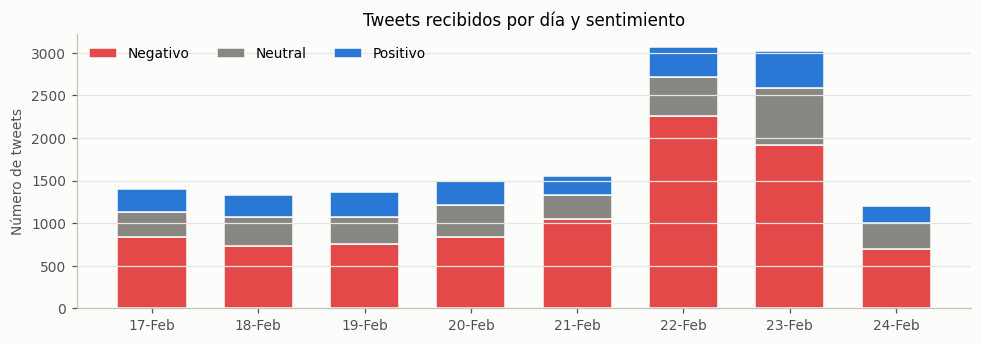

In [2]:
por_dia = (df.groupby([df.tweet_created.dt.date, "airline_sentiment"]).size()
             .unstack()[CLASES].iloc[1:])  # el primer dia solo tiene 4 tweets

fig, ax = plt.subplots(figsize=(9, 3.2))
abajo = np.zeros(len(por_dia))
etiquetas = [pd.Timestamp(d).strftime("%d-%b") for d in por_dia.index]
for c in CLASES:
    ax.bar(etiquetas, por_dia[c], bottom=abajo, color=COLOR[c], label=NOMBRES[c],
           width=0.65, edgecolor="#fcfcfb", linewidth=1)
    abajo += por_dia[c].values
ax.set_title("Tweets recibidos por día y sentimiento")
ax.set_ylabel("Número de tweets")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

**Figura 1.** Tweets recibidos por día. Los días 22 y 23 de febrero el volumen se duplicó (alrededor de 3,000 tweets diarios) por cancelaciones masivas, y la mayoría de los mensajes son quejas. Un equipo dimensionado para un día normal se satura en esos picos, que es justo cuando más importa responder rápido a los negativos.

### 2.3 Preprocesamiento y entrenamiento del clasificador

Se usa la misma limpieza de la práctica 3.1: se decodifican entidades HTML, se pasa a minúsculas, se eliminan menciones, se conservan las palabras de los hashtags, se expanden las negaciones ("can't" a "can not") y se eliminan números y signos. Las negaciones se conservan al quitar las *stopwords* porque invierten el sentimiento.

Se reserva el 20 % de los tweets como conjunto de prueba (estratificado por sentimiento). Ese conjunto se usa tanto para medir el clasificador como para simular la cola de atención.

In [3]:
NEGACIONES = {"no", "not", "nor", "never", "none", "nothing", "nobody", "nowhere", "cannot", "against"}
STOPWORDS = sorted(ENGLISH_STOP_WORDS - NEGACIONES)


def limpiar_tweet(texto):
    t = html.unescape(texto).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " url ", t)
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"#(\w+)", r" \1 ", t)
    t = re.sub(r"can't|cannot", "can not", t)
    t = re.sub(r"won't", "will not", t)
    t = re.sub(r"n't\b", " not", t.replace("\u2019", "'"))
    t = re.sub(r"'\w*", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["texto_limpio"] = df["text"].apply(limpiar_tweet)

train, test = train_test_split(df, test_size=0.2, stratify=df["airline_sentiment"], random_state=SEMILLA)

modelo = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=STOPWORDS, sublinear_tf=True)),
    ("clf", LogisticRegression(C=3, class_weight="balanced", max_iter=2000, random_state=SEMILLA)),
])
inicio = time.perf_counter()
modelo.fit(train["texto_limpio"], train["airline_sentiment"])
print(f"Entrenamiento: {len(train)} tweets en {time.perf_counter() - inicio:.2f} s   Prueba: {len(test)} tweets")

Entrenamiento: 11541 tweets en 0.51 s   Prueba: 2886 tweets


### 2.4 Simulación de la cola de atención

La función `simular_cola` reproduce el trabajo de un equipo de agentes:

- Los tweets de prueba llegan en el **minuto real** en que fueron publicados.
- Cada agente atiende un tweet a la vez. El tiempo de atención de cada tweet es aleatorio, con distribución exponencial y promedio de 5 minutos, y es el mismo para ese tweet en todas las políticas, para que la comparación sea justa.
- Cuando un agente se libera toma, de los tweets que ya llegaron, el de **menor valor de prioridad**; los empates se resuelven por orden de llegada.

Se comparan tres políticas, que solo difieren en el valor de prioridad:

| Política | Prioridad | Qué representa |
|---|---|---|
| FIFO | Igual para todos | Atención en orden de llegada (situación actual). |
| Prioridad IA | $-P(\text{negativo})$ estimada por el modelo | La técnica propuesta. |
| Prioridad ideal | 0 si el tweet es negativo según la etiqueta real, 1 si no | Referencia con un clasificador perfecto. |

El conjunto de prueba es el 20 % de los tweets, así que el escenario equivale a una quinta parte del equipo atendiendo una quinta parte de los mensajes. Se usan **2 agentes**, una capacidad suficiente para un día normal pero que se satura en los picos.

In [4]:
def simular_cola(llegadas, prioridad, duracion, agentes):
    """Devuelve la espera (minutos) de cada tweet hasta que un agente empieza a atenderlo."""
    n = len(llegadas)
    espera = np.zeros(n)
    libres = [0.0] * agentes          # minuto en que cada agente queda libre
    cola, i = [], 0
    while i < n or cola:
        t = heapq.heappop(libres)
        if not cola and llegadas[i] > t:   # nadie esperando: el agente aguarda al siguiente tweet
            t = llegadas[i]
        while i < n and llegadas[i] <= t:  # se forman en la cola los tweets que ya llegaron
            heapq.heappush(cola, (prioridad[i], llegadas[i], i))
            i += 1
        _, _, k = heapq.heappop(cola)
        espera[k] = t - llegadas[k]
        heapq.heappush(libres, t + duracion[k])
    return espera


test = test.sort_values("tweet_created").reset_index(drop=True)
llegadas = ((test.tweet_created - test.tweet_created.min()).dt.total_seconds() / 60).values
duracion = np.random.default_rng(SEMILLA).exponential(5, len(test))
es_negativo = (test["airline_sentiment"] == "negative").values

# Probabilidad de queja estimada por el modelo para cada tweet
p_negativo = modelo.predict_proba(test["texto_limpio"])[:, list(modelo.classes_).index("negative")]

POLITICAS = {
    "FIFO": np.zeros(len(test)),
    "Prioridad IA": -p_negativo,
    "Prioridad ideal": (~es_negativo).astype(float),
}
AGENTES = 2
esperas = {nombre: simular_cola(llegadas, prio, duracion, AGENTES) for nombre, prio in POLITICAS.items()}
print("Simulación terminada para", len(test), "tweets con", AGENTES, "agentes")

Simulación terminada para 2886 tweets con 2 agentes


## 3. Evaluación de la técnica de IA

### 3.1 Calidad y latencia del clasificador

In [5]:
pred = modelo.predict(test["texto_limpio"])
print(classification_report(test["airline_sentiment"], pred, labels=CLASES,
                            target_names=[NOMBRES[c] for c in CLASES], digits=3))
print(f"F1 macro: {f1_score(test['airline_sentiment'], pred, average='macro'):.3f}")
print(f"AUC ROC de P(negativo): {roc_auc_score(es_negativo, p_negativo):.3f}")

# Latencia: limpieza + vectorizacion + prediccion, un tweet a la vez como llegarian en tiempo real
muestra = test["text"].iloc[:500].tolist()
inicio = time.perf_counter()
for t in muestra:
    modelo.predict_proba([limpiar_tweet(t)])
latencia_ms = (time.perf_counter() - inicio) / len(muestra) * 1000
print(f"Latencia por tweet: {latencia_ms:.2f} ms")

              precision    recall  f1-score   support

    Negativo      0.884     0.802     0.841      1816
     Neutral      0.541     0.644     0.588       612
    Positivo      0.663     0.738     0.698       458

    accuracy                          0.758      2886
   macro avg      0.696     0.728     0.709      2886
weighted avg      0.776     0.758     0.765      2886

F1 macro: 0.709
AUC ROC de P(negativo): 0.897


Latencia por tweet: 0.42 ms


El clasificador obtiene un F1 macro de 0.709 y 76 % de exactitud, resultados consistentes con la práctica 3.1. Para esta aplicación la métrica más importante es el **AUC ROC de 0.897**: es la probabilidad de que una queja elegida al azar reciba un puntaje mayor que un tweet no negativo elegido al azar, es decir, el modelo ordena correctamente las quejas por encima del resto en casi 9 de cada 10 comparaciones. La clase negativa tiene una precisión de 0.88, así que pocos tweets reciben prioridad sin merecerla.

La **latencia es menor a medio milisegundo por tweet** (más de 2,000 tweets por segundo procesándolos uno a uno; el valor exacto varía un poco según la computadora), insignificante frente a esperas que se miden en minutos. Priorizar con IA no agrega retraso al sistema.

### 3.2 Tiempo de respuesta por política

In [6]:
def resumen(espera):
    return {
        "Espera prom. negativos (min)": espera[es_negativo].mean(),
        "Percentil 90 negativos (min)": np.percentile(espera[es_negativo], 90),
        "Negativos atendidos en menos de 1 h (%)": (espera[es_negativo] <= 60).mean() * 100,
        "Espera prom. no negativos (min)": espera[~es_negativo].mean(),
        "Espera prom. todos (min)": espera.mean(),
    }


tabla = pd.DataFrame({nombre: resumen(e) for nombre, e in esperas.items()}).T
reduccion = 1 - tabla.loc["Prioridad IA", "Espera prom. negativos (min)"] / tabla.loc["FIFO", "Espera prom. negativos (min)"]
print(f"Reducción de la espera promedio de los negativos con IA frente a FIFO: {reduccion:.0%}")
tabla.round(1)

Reducción de la espera promedio de los negativos con IA frente a FIFO: 62%


,Espera prom. negativos (min),Percentil 90 negativos (min),Negativos atendidos en menos de 1 h (%),Espera prom. no negativos (min),Espera prom. todos (min)
FIFO,195.5,531.1,53.2,165.2,184.2
Prioridad IA,74.6,133.8,88.0,350.6,176.9
Prioridad ideal,46.2,201.8,77.9,414.2,182.6


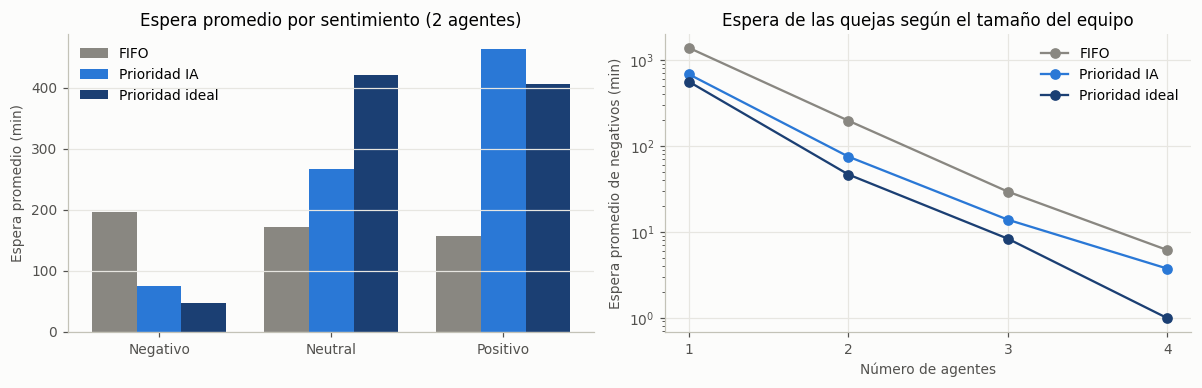

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

# Espera promedio por sentimiento y politica
x = np.arange(len(CLASES))
ancho = 0.26
for j, (nombre, e) in enumerate(esperas.items()):
    valores = [e[(test["airline_sentiment"] == c).values].mean() for c in CLASES]
    ax1.bar(x + (j - 1) * ancho, valores, ancho, color=COLOR_POLITICA[nombre], label=nombre)
ax1.set_xticks(x, [NOMBRES[c] for c in CLASES])
ax1.set_ylabel("Espera promedio (min)")
ax1.set_title(f"Espera promedio por sentimiento ({AGENTES} agentes)")
ax1.grid(axis="x", visible=False)
ax1.legend()

# Sensibilidad al tamano del equipo
equipos = [1, 2, 3, 4]
for nombre, prio in POLITICAS.items():
    medias = [simular_cola(llegadas, prio, duracion, a)[es_negativo].mean() for a in equipos]
    ax2.plot(equipos, medias, marker="o", color=COLOR_POLITICA[nombre], label=nombre)
ax2.set_yscale("log")
ax2.set_xticks(equipos)
ax2.set_xlabel("Número de agentes")
ax2.set_ylabel("Espera promedio de negativos (min)")
ax2.set_title("Espera de las quejas según el tamaño del equipo")
ax2.legend()
plt.tight_layout()
plt.show()

**Figura 2.** Espera promedio por sentimiento con 2 agentes (izquierda) y espera promedio de los tweets negativos al variar el número de agentes (derecha, escala logarítmica).

### 3.3 Interpretación de los resultados

- **La IA reduce 62 % la espera promedio de las quejas**, de 196 a 75 minutos, con el mismo equipo de 2 agentes. La proporción de quejas que empiezan a atenderse en menos de una hora sube de 53 % a 88 %.
- **La mejora se mantiene con cualquier tamaño de equipo.** En la Figura 2 (derecha), la curva de Prioridad IA queda por debajo de FIFO de 1 a 4 agentes; por ejemplo, con 3 agentes la espera de las quejas baja de 29 a 14 minutos. Con 2 agentes, la IA deja a las quejas en un punto intermedio entre lo que lograría FIFO con 2 y con 3 agentes, sin contratar a nadie.
- **La espera total no cambia** (184 contra 177 minutos en promedio): priorizar no crea capacidad, solo **redistribuye** la espera hacia los tweets que pueden esperar. Los neutrales y positivos pasan de 165 a 351 minutos en promedio. Es un costo aceptable, porque un agradecimiento no requiere una respuesta urgente, pero en producción convendría añadir un envejecimiento (*aging*): aumentar la prioridad de un tweet conforme espera, para que ninguno quede sin respuesta.
- **Comparación con la prioridad ideal.** Con un clasificador perfecto la espera promedio de las quejas sería de 46 minutos; la IA obtiene 75, con lo que alcanza el 81 % de la mejora posible ((196 - 75) / (196 - 46)). La diferencia se debe a las quejas que el modelo no reconoce (exhaustividad de 0.80): quedan con baja prioridad y esperan mucho, lo que eleva el promedio. En cambio, la IA tiene mejor percentil 90 y más quejas atendidas en menos de una hora que la prioridad ideal, porque ordena las quejas por la seguridad del modelo y no por llegada: en un pico atiende rápido a la mayoría de las nuevas quejas, a costa de que unas pocas, las menos claras, esperen más.
- **Los neutrales esperan menos con IA que con la prioridad ideal.** Muchos neutrales son preguntas ("¿a qué hora abre la puerta?") que el modelo confunde con quejas y les da prioridad. Desde el punto de vista del negocio no es grave, porque una pregunta también espera respuesta.

**Limitaciones.** La simulación usa un tiempo de atención promedio supuesto (5 minutos) y un equipo proporcional al 20 % de los tweets; los valores absolutos cambian con esos supuestos, aunque la ventaja relativa de priorizar se mantiene en todos los tamaños de equipo probados. Además, el modelo hereda las limitaciones de TF-IDF: no detecta el sarcasmo y el dataset es de 2015 y en inglés.

## 4. Conclusiones

La práctica mostró que la IA puede optimizar el tiempo de respuesta en redes sociales sin aumentar los recursos: basta con decidir mejor **qué mensaje atender primero**. Un clasificador de sentimiento sencillo (TF-IDF con Regresión Logística), entrenado en menos de un segundo, asigna a cada tweet la probabilidad de ser una queja con un AUC ROC de 0.90 y una latencia menor a medio milisegundo. Al usar esa probabilidad para ordenar la cola de atención, la espera promedio de las quejas bajó 62 % (de 196 a 75 minutos) y el porcentaje de quejas atendidas en menos de una hora pasó de 53 % a 88 %, con el mismo equipo de agentes.

El análisis también dejó claras las condiciones para que la técnica funcione. Primero, el modelo debe ser rápido: por eso se eligió un modelo lineal y no un Transformer, que en la práctica 3.1 resultó más de cien veces más lento. Segundo, el beneficio es mayor cuando el equipo está saturado, como en los días de cancelaciones masivas, que es justo cuando más importa responder rápido. Tercero, priorizar redistribuye la espera, por lo que los mensajes no urgentes se atienden más tarde y conviene complementar la política con un mecanismo de envejecimiento.

Como mejoras se propone combinar el sentimiento con el motivo de la queja (por ejemplo, dar más urgencia a vuelos cancelados que a quejas sobre la comida), usar los temas de NMF de la práctica 3.1 para enviar cada queja al equipo especializado y reentrenar el modelo periódicamente con mensajes recientes.

## Referencias

- CrowdFlower. (2016). *Twitter US Airline Sentiment* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
- Hernández Parada, M. S. (2026). *Análisis, implementación y prueba de técnicas de IA a un Dataset de Redes Sociales para optimizar el tiempo de respuesta* [Notebook de Jupyter]. GitHub. [Ver en GitHub](https://github.com/RKCbas/LENGUAJES-DE-CIENCIA-DE-DATOS-B-SICO---PRACTICAS/blob/main/Cuatrimestre%204/9%20-%20T%C3%B3picos%20de%20IA%20para%20la%20transformaci%C3%B3n%20digital/Practica%203.2/An%C3%A1lisis%2C%20implementaci%C3%B3n%20y%20prueba%20de%20t%C3%A9cnicas%20de%20IA%20a%20un%20Dataset%20de%20Redes%20Sociales%20para%20optimizar%20el%20tiempo%20de%20respuesta.ipynb)
- Hernández Parada, M. S. (2026). *Análisis, implementación y prueba de técnicas de IA a un Dataset de Redes Sociales* [Notebook de Jupyter]. GitHub. [Ver en GitHub](https://github.com/RKCbas/LENGUAJES-DE-CIENCIA-DE-DATOS-B-SICO---PRACTICAS/blob/main/Cuatrimestre%204/9%20-%20T%C3%B3picos%20de%20IA%20para%20la%20transformaci%C3%B3n%20digital/Practica%203.1/An%C3%A1lisis%2C%20implementaci%C3%B3n%20y%20prueba%20de%20t%C3%A9cnicas%20de%20IA%20a%20un%20Dataset%20de%20Redes%20Sociales.ipynb)
- Kleinrock, L. (1976). *Queueing Systems, Volume 2: Computer Applications*. Wiley.
- Manning, C. D., Raghavan, P. y Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.